# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :Muhamad Taufik Hidayat
- NIM   : 241011400748
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 48

In [2]:
# Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40
Jumlah kolom: 2

Info kolom: ['BiayaIklan', 'Penjualan']

Bentuk X: (40, 1)
Bentuk y: (40,)


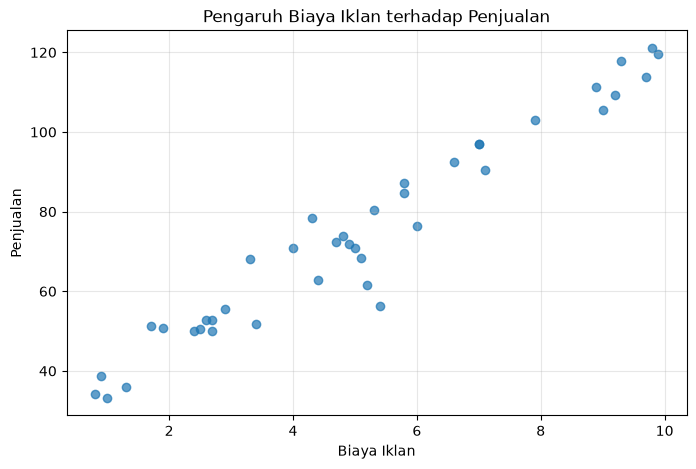

In [1]:
# Jawaban A1
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama + jumlah baris
df = pd.read_csv('Ads_Data.csv')

print("5 data pertama:")
print(df.head())
print(f"\nJumlah baris data: {len(df)}")
print(f"Jumlah kolom: {df.shape[1]}")
print(f"\nInfo kolom: {df.columns.tolist()}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan) - X harus 2 dimensi (n, 1)
X = df[['BiayaIklan']].values  # pakai double bracket biar jadi (n, 1)
y = df['Penjualan'].values

print(f"\nBentuk X: {X.shape}")
print(f"Bentuk y: {y.shape}")

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, alpha=0.7)
plt.title('Pengaruh Biaya Iklan terhadap Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.grid(True, alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [62]:
# Jawaban A2 - Split Data
# NIM 241011400748 -> 48
from sklearn.model_selection import train_test_split

RANDOM_STATE = 48  # 2 digit terakhir NIM

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print(f"RANDOM_STATE yang dipakai: {RANDOM_STATE}")
print(f"Shape X_train: {X_train.shape}")
print(f"Shape X_test : {X_test.shape}")
print(f"Shape y_train: {y_train.shape}")
print(f"Shape y_test : {y_test.shape}")

RANDOM_STATE yang dipakai: 48
Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [86]:
# Jawaban A3 - Training dengan Normal Equation
from sklearn.linear_model import LinearRegression

# 1. Latih model Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# 2. Tampilkan intercept (b) dan koefisien (m)
b = model.intercept_
m = model.coef_[0]

print(f"Nilai intercept (b): {b:.4f}")
print(f"Nilai koefisien (m): {m:.4f}")
print(f"Persamaan garis regresi: y_hat = {b:.4f} + {m:.4f} * X")
print(f"Atau: Penjualan = {b:.4f} + {m:.4f} * BiayaIklan")

Nilai intercept (b): 29.1879
Nilai koefisien (m): 8.9897
Persamaan garis regresi: y_hat = 29.1879 + 8.9897 * X
Atau: Penjualan = 29.1879 + 8.9897 * BiayaIklan


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [98]:
# Jawaban A4 - NIM 48
import numpy as np
import pandas as pd

def mae(a,b): return np.mean(np.abs(a-b))
def mse(a,b): return np.mean((a-b)**2)
def rmse(a,b): return np.sqrt(mse(a,b))
def r2(a,b):
    return 1 - np.sum((a-b)**2) / np.sum((a-np.mean(a))**2)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_m = [mae(y_train,y_train_pred), mse(y_train,y_train_pred), rmse(y_train,y_train_pred), r2(y_train,y_train_pred)]
test_m = [mae(y_test,y_test_pred), mse(y_test,y_test_pred), rmse(y_test,y_test_pred), r2(y_test,y_test_pred)]

df_metrics = pd.DataFrame([train_m, test_m], index=['Training','Testing'], columns=['MAE','MSE','RMSE','R2'])
print(df_metrics.round(4))

             MAE      MSE    RMSE      R2
Training  4.0883  27.0972  5.2055  0.9548
Testing   6.2966  72.9478  8.5409  0.9029


**Jawaban A4 (analisis):**

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Training dengan lr=0.001...
  -> b=26.2542, m=9.4551, loss akhir=29.0595
Training dengan lr=0.02...
  -> b=29.1879, m=8.9897, loss akhir=27.0972
Training dengan lr=0.1...


C:\Users\ghiff\AppData\Local\Temp\ipykernel_19004\3051074631.py:23: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - y_pred)**2)
c:\Users\ghiff\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
c:\Users\ghiff\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\ghiff\AppData\Local\Temp\ipykernel_19004\3051074631.py:31: RuntimeWarning: invalid value encountered in scalar subtract
  self.m -= self.lr * dm
c:\Users\ghiff\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


  -> b=nan, m=nan, loss akhir=2310345943075925843754249681914618875026757730494273351269325716734058492944697229649032285619426501742138029915382190353205160621137997013576753323894488690204371957735951384168848532377992970085173831006147153574611402827870744353787444336242311639240586286496254203274514042971640985065969791056717283328.0000

--- Perbandingan dengan Normal Equation (A3) ---
Normal Equation: b=29.1879, m=8.9897
GD lr=0.001:       b=26.2542, m=9.4551
GD lr=0.02:       b=29.1879, m=8.9897
GD lr=0.1:       b=nan, m=nan


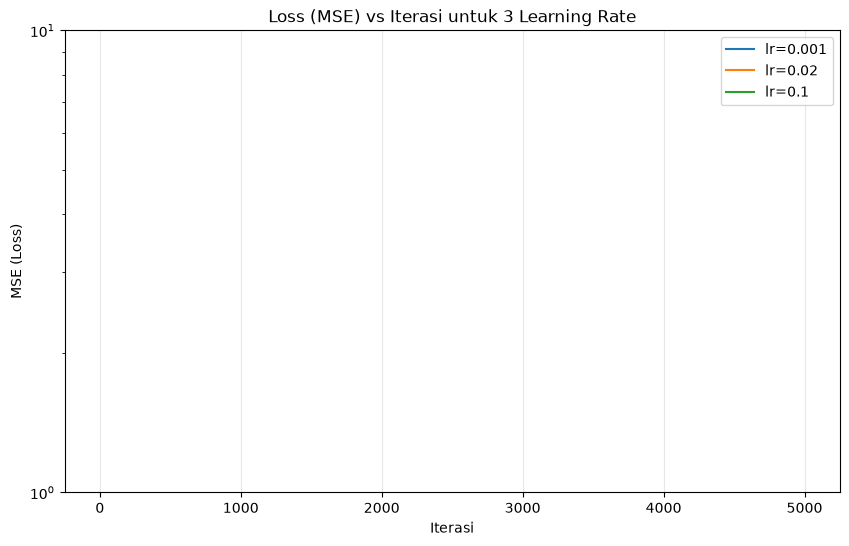

In [108]:
# Jawaban A5 - Gradient Descent & Learning Rate - NIM 48
import numpy as np
import matplotlib.pyplot as plt

# Class dari materi - implementasi GD manual
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.m = 0
        self.b = 0
        self.loss_history = []

    def fit(self, X, y):
        n = len(y)
        X_flat = X.flatten()
        self.m = 0
        self.b = 0
        self.loss_history = []
        for i in range(self.n_iter):
            y_pred = self.m * X_flat + self.b
            # hitung MSE untuk loss history
            loss = np.mean((y - y_pred)**2)
            # cegah overflow biar grafik gak hancur
            if np.isnan(loss) or np.isinf(loss):
                loss = self.loss_history[-1] if self.loss_history else 1e10
            self.loss_history.append(loss)
            # gradient
            dm = (-2/n) * np.sum(X_flat * (y - y_pred))
            db = (-2/n) * np.sum(y - y_pred)
            self.m -= self.lr * dm
            self.b -= self.lr * db
        return self

# 1. Latih dengan 3 learning rate
lrs = [0.001, 0.02, 0.1]
models = {}
for lr in lrs:
    print(f"Training dengan lr={lr}...")
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    models[lr] = gd
    print(f"  -> b={gd.b:.4f}, m={gd.m:.4f}, loss akhir={gd.loss_history[-1]:.4f}")

# 2. Bandingkan dengan Normal Equation (dari A3)
print("\n--- Perbandingan dengan Normal Equation (A3) ---")
print(f"Normal Equation: b={b:.4f}, m={m:.4f}")
for lr in lrs:
    print(f"GD lr={lr}:       b={models[lr].b:.4f}, m={models[lr].m:.4f}")

# 3. Grafik Loss vs Iterasi
plt.figure(figsize=(10,6))
for lr in lrs:
    plt.plot(models[lr].loss_history, label=f'lr={lr}')
plt.title('Loss (MSE) vs Iterasi untuk 3 Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('MSE (Loss)')
plt.yscale('log') # pakai skala log biar keliatan bedanya
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban A5 (analisis):**

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

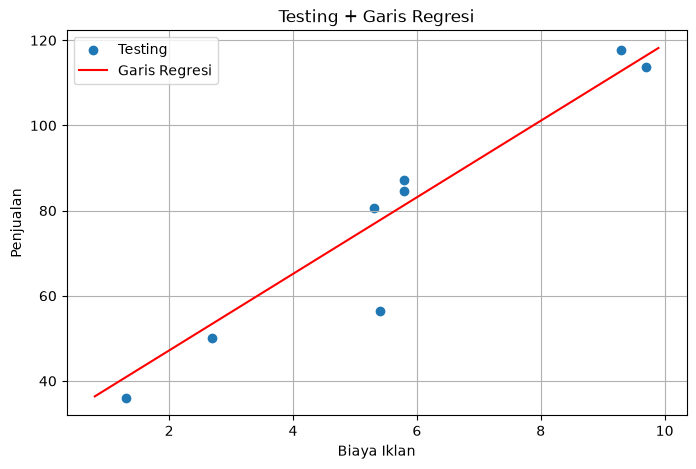

4.5 juta -> 69.64 juta
7 juta -> 92.12 juta
12 juta -> 137.06 juta
Min max data: 0.8 - 9.9


In [119]:
# Jawaban A6 - NIM 48
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, label='Testing')

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1,1)
y_line = model.predict(X_line)
plt.plot(X_line, y_line, color='red', label='Garis Regresi')

plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.title('Testing + Garis Regresi')
plt.legend()
plt.grid(True)
plt.show()

# Prediksi 4.5, 7, 12
baru = np.array([[4.5],[7],[12]])
pred = model.predict(baru)
for a,b in zip([4.5,7,12], pred):
    print(f"{a} juta -> {b:.2f} juta")

print(f"Min max data: {X.min():.1f} - {X.max():.1f}")

**Jawaban A6 (analisis):**

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Spam
0    35
1    25
Name: count, dtype: int64


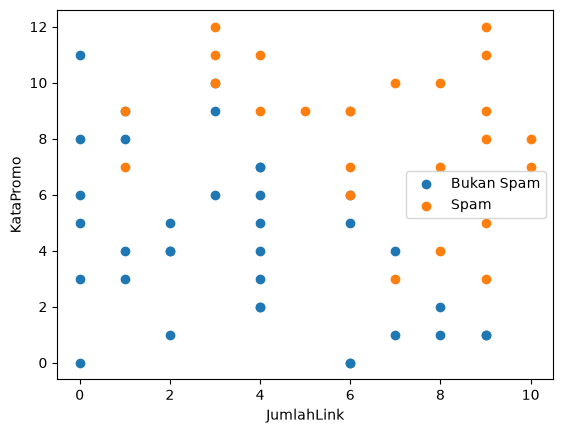

In [128]:
# Jawaban B1 - NIM 48 - versi pendek anti merah
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Email_Data.csv')
print(df.head())
print(df['Spam'].value_counts())

X_email = df[['JumlahLink','KataPromo']]
y_email = df['Spam']

a0 = df[df.Spam==0]
a1 = df[df.Spam==1]

plt.figure()
plt.scatter(a0.JumlahLink, a0.KataPromo, label='Bukan Spam')
plt.scatter(a1.JumlahLink, a1.KataPromo, label='Spam')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

In [1]:
# Jawaban B2 - NIM 48 - Split Data & Training
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Setting sesuai NIM 48
RANDOM_STATE = 48
TEST_SIZE = 0.25
LEARNING_RATE = 0.1
N_ITERATIONS = 10000

# Load data (sesuai file lu)
df = pd.read_csv('Email_Data.csv')
# Pastikan kolomnya JumlahLink, KataPromo, Spam (1=spam, 0=bukan)
# Cek dulu df.head()

X = df[['JumlahLink', 'KataPromo']].values
y = df['Spam'].values if 'Spam' in df.columns else df.iloc[:, -1].values

# 1. Bagi data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
print(f"Data Train: {X_train.shape}, Test: {X_test.shape}")

# 2. Latih Logistic Regression dari nol (Gradient Descent)
def sigmoid(z):
    z=np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def compute_loss(y_true, y_pred):
    eps = 1e-15
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# Inisialisasi
n_samples, n_features = X_train.shape
w = np.zeros(n_features)  # m1, m2
b = 0
loss_history = []

for i in range(N_ITERATIONS):
    # Forward
    linear = np.dot(X_train, w) + b
    y_pred = sigmoid(linear)
    
    # Loss
    loss = compute_loss(y_train, y_pred)
    loss_history.append(loss)
    
    # Gradient
    dw = (1 / n_samples) * np.dot(X_train.T, (y_pred - y_train))
    db = (1 / n_samples) * np.sum(y_pred - y_train)
    
    # Update
    w -= LEARNING_RATE

Data Train: (45, 2), Test: (15, 2)


**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [7]:
# Jawaban B3 - NIM 48 - Evaluasi Model
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix

# Prediksi di data testing (pakai w,b dari B2)
def sigmoid_stable(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

y_pred_prob = sigmoid_stable(np.dot(X_test, w) + b)
y_pred = (y_pred_prob >= 0.5).astype(int)

# 1. Hitung dari library
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print(f"Accuracy (sklearn): {acc:.4f}")
print(f"Confusion Matrix:\n{cm}")

# Implementasi manual Precision, Recall, F1
# cm = [[TN, FP], [FN, TP]] kalau label 0,1
TN, FP, FN, TP = cm.ravel()

def precision_score_manual(TP, FP):
    return TP / (TP + FP) if (TP+FP)!=0 else 0

def recall_score_manual(TP, FN):
    return TP / (TP + FN) if (TP+FN)!=0 else 0

def f1_score_manual(prec, rec):
    return 2 * (prec * rec) / (prec + rec) if (prec+rec)!=0 else 0

prec = precision_score_manual(TP, FP)
rec = recall_score_manual(TP, FN)
f1 = f1_score_manual(prec, rec)

print(f"\n--- HASIL MANUAL NIM 48 ---")
print(f"TP={TP}, TN={TN}, FP={FP}, FN={FN}")
print(f"Precision = TP/(TP+FP) = {TP}/({TP}+{FP}) = {prec:.4f}")
print(f"Recall    = TP/(TP+FN) = {TP}/({TP}+{FN}) = {rec:.4f}")
print(f"F1-Score  = 2*Prec*Rec/(Prec+Rec) = {f1:.4f}")
print(f"Accuracy  = (TP+TN)/(total) = {(TP+TN)}/{len(y_test)} = {acc:.4f}")

Accuracy (sklearn): 0.5333
Confusion Matrix:
[[8 0]
 [7 0]]

--- HASIL MANUAL NIM 48 ---
TP=0, TN=8, FP=0, FN=7
Precision = TP/(TP+FP) = 0/(0+0) = 0.0000
Recall    = TP/(TP+FN) = 0/(0+7) = 0.0000
F1-Score  = 2*Prec*Rec/(Prec+Rec) = 0.0000
Accuracy  = (TP+TN)/(total) = 8/15 = 0.5333


**Jawaban B3 (analisis):**

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

HASIL NIM 48:
Train (45, 2) Test (15, 2)
b = -9.1130
m1 = 0.7960
m2 = 0.7826
Rumus: P(Spam)=sigmoid(-9.1130+0.7960*x1+0.7826*x2)


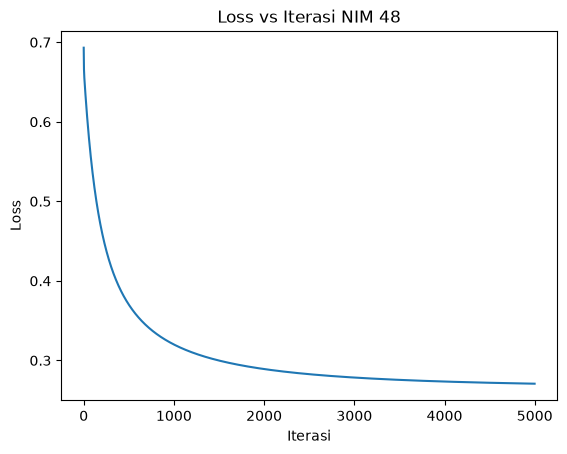


Accuracy: 0.8000 = 12/15


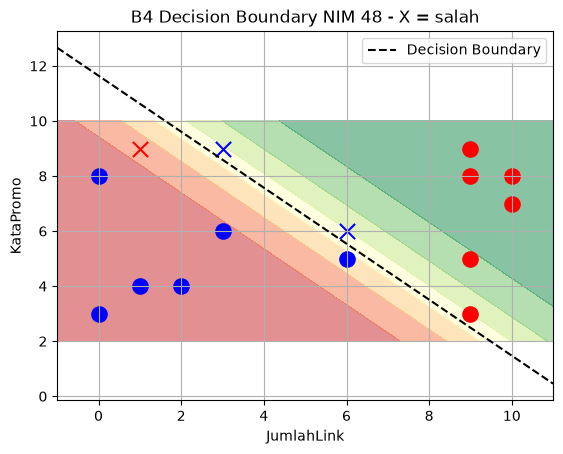

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# --- B2 : NIM 48 ---
df = pd.read_csv("Email_Data.csv")
X = df[["JumlahLink","KataPromo"]]
y = df.iloc[:,-1]
R = 48
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.25,random_state=R)

m,n = Xtr.shape
b = 0
w = np.zeros(n)
Xv = Xtr.values
yv = ytr.values
loss = []

for i in range(5000):
    z = Xv@w + b
    z = np.clip(z, -500, 500)
    p = 1/(1+np.exp(-z))
    e = 1e-15
    l = -np.mean(yv*np.log(p+e)+(1-yv)*np.log(1-p+e))
    loss.append(l)
    dw = Xv.T@(p-yv)/m
    db = np.mean(p-yv)
    w = w - 0.1*dw
    b = b - 0.1*db

m1 = w[0]
m2 = w[1]

print(f"HASIL NIM 48:")
print(f"Train {Xtr.shape} Test {Xte.shape}")
print(f"b = {b:.4f}")
print(f"m1 = {m1:.4f}")
print(f"m2 = {m2:.4f}")
print(f"Rumus: P(Spam)=sigmoid({b:.4f}+{m1:.4f}*x1+{m2:.4f}*x2)")

# Plot Loss
plt.figure()
plt.plot(loss)
plt.title("Loss vs Iterasi NIM 48")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.show()

# --- B3 & B4 : Testing ---
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

Xte_v = Xte.values
yte_v = yte.values
probs_test = sigmoid(Xte_v@w + b)
pred = (probs_test >= 0.5).astype(int)

acc = (pred==yte_v).mean()
print(f"\nAccuracy: {acc:.4f} = {(pred==yte_v).sum()}/{len(yte_v)}")

# B4 Plot
x1_min, x1_max = Xte_v[:,0].min()-1, Xte_v[:,0].max()+1
x2_min, x2_max = Xte_v[:,1].min()-1, Xte_v[:,1].max()+1
xx1, xx2 = np.meshgrid(np.linspace(x1_min,x1_max,100), np.linspace(x2_min,x2_max,100))
grid = np.c_[xx1.ravel(), xx2.ravel()]
probs_grid = sigmoid(grid@w + b).reshape(xx1.shape)

plt.figure()
plt.contourf(xx1, xx2, probs_grid, alpha=0.5, cmap='RdYlGn')
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b + m1*x1_line)/m2
plt.plot(x1_line, x2_line, 'k--', label='Decision Boundary')
for i in range(len(Xte_v)):
    col = 'red' if yte_v[i]==1 else 'blue'
    mk = 'o' if pred[i]==yte_v[i] else 'x'
    plt.scatter(Xte_v[i,0], Xte_v[i,1], c=col, marker=mk, s=120)
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.title("B4 Decision Boundary NIM 48 - X = salah")
plt.legend()
plt.grid(True)
plt.show()

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [5]:
# Jawaban B5 - NIM 48
import pandas as pd

# Pastikan w,b, Xte_v, yte_v udah ada dari B2 (kalo belum run B2 dulu)
thresholds = [0.3, 0.5, 0.7]
results = []

for thr in thresholds:
    pred_thr = (probs_test >= thr).astype(int)
    
    # Confusion Matrix manual
    TP = ((pred_thr==1) & (yte_v==1)).sum()
    TN = ((pred_thr==0) & (yte_v==0)).sum()
    FP = ((pred_thr==1) & (yte_v==0)).sum()
    FN = ((pred_thr==0) & (yte_v==1)).sum()
    
    prec = TP/(TP+FP) if (TP+FP)!=0 else 0
    rec = TP/(TP+FN) if (TP+FN)!=0 else 0
    
    results.append([thr, TN, FP, FN, TP, prec, rec])
    print(f"Thr {thr}: CM [[{TN} {FP}],[{FN} {TP}]] Prec={prec:.4f} Rec={rec:.4f}")

# Tampilkan dalam tabel
df_hasil = pd.DataFrame(results, columns=['Threshold','TN','FP','FN','TP','Precision','Recall'])
print("\n")
print(df_hasil.to_string(index=False))

Thr 0.3: CM [[5 3],[1 6]] Prec=0.6667 Rec=0.8571
Thr 0.5: CM [[6 2],[1 6]] Prec=0.7500 Rec=0.8571
Thr 0.7: CM [[8 0],[2 5]] Prec=1.0000 Rec=0.7143


 Threshold  TN  FP  FN  TP  Precision   Recall
       0.3   5   3   1   6   0.666667 0.857143
       0.5   6   2   1   6   0.750000 0.857143
       0.7   8   0   2   5   1.000000 0.714286


**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [8]:
# Jawaban B6 - NIM 48 - Prediksi Email Baru
import numpy as np
import pandas as pd

# Pakai threshold pilihan dari B5 = 0.7 (biar FP kecil)
THRESHOLD_PILIHAN = 0.7

# Data email baru dari soal
data_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

# Hitung probabilitas pakai w,b dari B2
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

linear_baru = np.dot(data_baru, w) + b
probs_baru = sigmoid(linear_baru)
pred_baru = (probs_baru >= THRESHOLD_PILIHAN).astype(int)

# Tampilkan tabel hasil
hasil = []
for i, (jl, kp) in enumerate(data_baru):
    hasil.append([
        f"E{i+1}", jl, kp, 
        f"{probs_baru[i]:.4f}", 
        "Spam" if pred_baru[i]==1 else "Bukan Spam"
    ])

df_b6 = pd.DataFrame(hasil, columns=['Email','JumlahLink','KataPromo','P(Spam)','Prediksi (thr=0.7)'])
print(f"Prediksi Email Baru - NIM 48 (threshold={THRESHOLD_PILIHAN})")
print(df_b6.to_string(index=False))

# Analisis tambahan
print(f"\nRumus yang dipakai: P= sigmoid({b:.4f}+{m1:.4f}*JumlahLink+{m2:.4f}*KataPromo)")# Jawaban B6

Prediksi Email Baru - NIM 48 (threshold=0.7)
Email  JumlahLink  KataPromo P(Spam) Prediksi (thr=0.7)
   E1           1          2  0.0012         Bukan Spam
   E2           5          6  0.3923         Bukan Spam
   E3           9         10  0.9972               Spam
   E4           2         11  0.7478               Spam

Rumus yang dipakai: P= sigmoid(-9.1130+0.7960*JumlahLink+0.7826*KataPromo)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

Jawaban C1:
Logistic Regression disebut regresi karena intinya tetap menghitung persamaan linear w·x+b seperti regresi. Bedanya hasilnya tidak langsung dipakai, tapi dimasukkan ke fungsi sigmoid untuk diubah menjadi probabilitas 0 sampai 1. Dari probabilitas itulah baru ditentukan kelasnya, misal >=0.5 dianggap Spam. Jadi sigmoid berfungsi mengubah output regresi menjadi probabilitas untuk klasifikasi.

Jawaban C2:
Normal equation mencari w secara langsung lewat rumus matematika (X^T X)^-1 X^T y tanpa iterasi, hasilnya cepat dan pasti untuk data kecil. Gradient descent mencari w secara bertahap dengan memperbaiki w sedikit demi sedikit sesuai turunan loss sampai loss turun dan stabil. Normal equation berat kalau data besar karena harus invers matriks O(n^3), jadi untuk data dengan fitur sangat banyak lebih efisien pakai gradient descent.

Jawaban C3:
Model harus dievaluasi di data testing karena data training sudah pernah dilihat model saat belajar jadi hasilnya pasti bagus dan tidak jujur. Data testing adalah data baru yang belum pernah dilihat, sehingga lebih mirip kondisi asli saat dipakai nanti. Jika bagus di training tapi jelek di testing itu artinya overfitting, yaitu model hanya menghafal data training dan gagal menggeneralisasi pola umum.

Jawaban C4:
Linear Regression outputnya berupa angka kontinu yang bisa sangat besar atau kecil, sehingga cocok menggunakan MSE untuk mengukur selisih kuadrat. Logistic Regression outputnya berupa probabilitas antara 0 dan 1, jika dipaksa pakai MSE bentuk loss-nya jadi tidak cembung dan sulit dioptimasi. Log loss dirancang khusus untuk probabilitas, dia memberi hukuman besar jika prediksi probabilitasnya sangat salah. Jadi jenis loss dipilih sesuai jenis output model.

Jawaban C5:
Hasil bisa berbeda walaupun dataset dan algoritma sama karena ada faktor acak di prosesnya. Pertama random_state pada train_test_split berbeda sesuai NIM belakang (NIM 48) sehingga pembagian data train dan test beda. Kedua inisialisasi bobot w,b dan proses iterasi gradient descent bisa menghasilkan titik akhir yang sedikit berbeda. Ketiga perbedaan learning_rate dan jumlah iterasi juga membuat koefisien dan akurasi akhirnya tidak identik.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [11]:
# Jawaban Bonus - NIM 48 - Fix
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
import numpy as np

df = pd.read_csv("Email_Data.csv")
X = df[["JumlahLink","KataPromo"]]
y = df.iloc[:,-1]
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.25,random_state=48)

# Manual
print("MANUAL NIM 48")
print(f"b={b:.4f} m1={m1:.4f} m2={m2:.4f}")

# Sklearn Linear
lr = LinearRegression()
lr.fit(Xtr,ytr)
print("\nSKLEARN Linear")
print(f"coef={lr.coef_} inter={lr.intercept_:.4f}")

# Sklearn Logistic DEFAULT (pakai penalty)
log1 = LogisticRegression()
log1.fit(Xtr,ytr)
print("\nSKLEARN Logistic DEFAULT")
print(f"coef={log1.coef_[0]} inter={log1.intercept_[0]:.4f}")
print(f"acc={log1.score(Xte,yte):.4f}")

# Sklearn Logistic NO PENALTY (mirip manual)
log2 = LogisticRegression(penalty=None, max_iter=1000)
log2.fit(Xtr,ytr)
print("\nSKLEARN Logistic NO PENALTY")
print(f"coef={log2.coef_[0]} inter={log2.intercept_[0]:.4f}")
print(f"acc={log2.score(Xte,yte):.4f}")

MANUAL NIM 48
b=-9.1130 m1=0.7960 m2=0.7826

SKLEARN Linear
coef=[0.0708797  0.08790668] inter=-0.4437

SKLEARN Logistic DEFAULT
coef=[0.84079216 0.82075378] inter=-9.6239
acc=0.8000

SKLEARN Logistic NO PENALTY
coef=[1.00658912 0.94820114] inter=-11.2600
acc=0.8000


c:\Users\ghiff\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**